# RetailMind AI — Day 11: a VAE that draws extra pictures for a thin category

Some categories have few training pictures, and the classifier is weakest there. Can a **VAE** (a network that learns to draw new pictures like its training pictures) make extra pictures that help?

We pretend we only have **100 shirt pictures** (the weakest category on Day 6) and 1,000 of every other category. Training takes about 15 minutes, so this notebook **reads the saved results** from `python -m src.train_day11`, and draws a few new pictures live from the saved VAE.

In [1]:
# Work from the project root so the `src` package can be imported
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)
os.environ.setdefault("KERAS_BACKEND", "tensorflow")     # this project uses TensorFlow, whatever ~/.keras/keras.json says
print("project folder:", os.path.basename(ROOT))

project folder: day3-4


## 1. Which category needs help, and how thin is it?

In [2]:
import json
day11 = json.load(open("models/day11_results.json"))
print("weakest category on Day 6:", day11["thin_category"], "- recall", day11["day6_recall"])
print("pictures of it we pretend to have:", day11["real_pictures_kept"], "| of every other category:", day11["other_pictures_per_category"])
print("pictures the VAE drew:", day11["drawn_total"])

weakest category on Day 6: Shirt - recall 0.731
pictures of it we pretend to have: 100 | of every other category: 1000
pictures the VAE drew: 900


## 2. Look at the pictures

Top: real shirts. Below: the VAE's drawings.

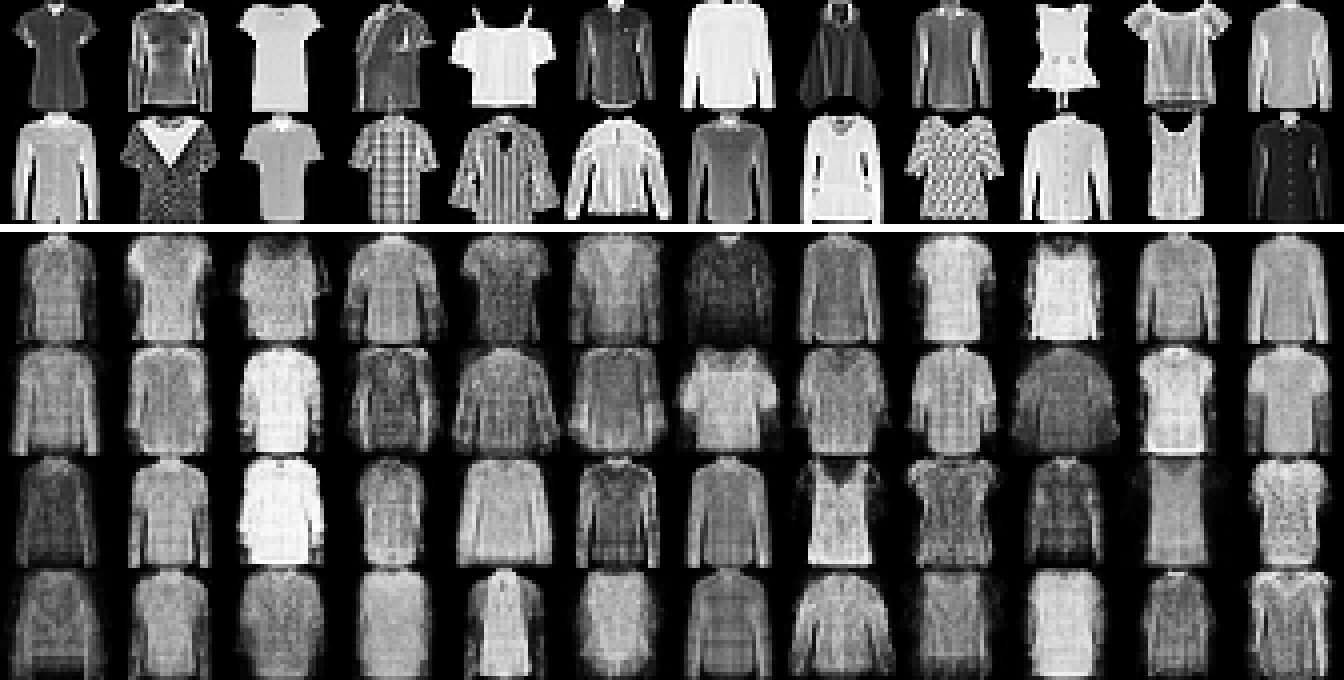

In [3]:
from IPython.display import Image, display
display(Image("reports/day11_samples.png", width=720))

## 3. Are the drawn pictures any good? (the checks from the script)

In [4]:
for name, value in day11["inspection"].items():
    print(f"{name:<30}{value}")

real_to_real_nearest_mean     5.007
drawn_to_real_nearest_mean    4.19
limit_used_to_keep            7.861
drawn_kept                    900
drawn_total                   900
variety_between_real          9.523
variety_between_drawn         6.827
mean_brightness_real          0.328
mean_brightness_drawn         0.3115


## 4. Did they help the classifier? (average of 5 random starts)

The control is the cheapest idea: just repeat the 100 real pictures until there are 1,000.

In [5]:
print(f"{'Training set':<28}{'Shirt recall':>16}{'accuracy':>11}{'other 9 cats':>14}{'T-shirt':>9}")
for name, s in day11["setups"].items():
    print(f"{name:<28}{s['thin_recall_mean']:>9.3f} +-{s['thin_recall_std']:.3f}{s['accuracy_mean']:>10.4f}{s['other_categories_recall_mean']:>14.4f}{s['tshirt_recall_mean']:>9.4f}")
print()
for name, s in day11["setups"].items():
    print(f"{name:<28} Shirt recall per start: {s['thin_recall_per_seed']}")

Training set                    Shirt recall   accuracy  other 9 cats  T-shirt
thin data only                  0.082 +-0.083    0.8411        0.9254   0.9058
real pictures repeated          0.273 +-0.053    0.8602        0.9255   0.9106
thin data + VAE pictures        0.185 +-0.037    0.8507        0.9247   0.9022

thin data only               Shirt recall per start: [0.142, 0.038, 0.013, 0.003, 0.215]
real pictures repeated       Shirt recall per start: [0.238, 0.342, 0.19, 0.306, 0.287]
thin data + VAE pictures     Shirt recall per start: [0.176, 0.239, 0.159, 0.137, 0.214]


## 5. Draw new pictures live from the saved VAE

In [6]:
import numpy as np, keras
from src.config import VAE_DECODER_FILE

decoder = keras.models.load_model(VAE_DECODER_FILE)
codes = np.random.RandomState(7).normal(size=(5, 8)).astype("float32")     # random points near the bell curve
new = decoder.predict(codes, verbose=0).reshape(5, 28, 28)
print("drawn pictures:", new.shape, "| brightness range per picture:", [f"{p.min():.2f}-{p.max():.2f}" for p in new])
shades = " .:-=+*#%@"
for row in new[0, ::2]:
    print("".join(shades[int(v * 9.99)] for v in row))

drawn pictures: (5, 28, 28) | brightness range per picture: ['0.00-0.70', '0.00-0.87', '0.00-0.90', '0.00-0.75', '0.00-0.94']
       .  :-.....:.         
       :++=+=+==++==:       
       .-****+=++++=.       
       .-=-==+===-==.       
       :*==+===-=--*-       
       -=*=-==-=---*=.      
       -:++===-===*+:.      
       ---+:=*=-++==:-      
      ::=++-+*==++-+-::     
      =-===---=+--==+-:     
     .==++*+=+++==*+*+=:    
    . -=-:==----::-:--.-    
    . --:::.::-...:::=.-    
     .::.   ...     .+.:    


## 6. Conclusion

- **The VAE pictures helped, but plain repetition helped more.** Shirt recall: 0.08 with thin data, 0.19 with VAE pictures, 0.27 with the 100 real pictures repeated (and the repeated version won all 5 pairs of matching runs).
- **No harm to the other categories** (0.925 either way), but even the best setup is far from the 0.73 that 60 times more real shirts give.
- **The drawings are blurry and look alike** (variety 6.8 vs 9.5 for real shirts): a mild mode collapse. The "keep only realistic ones" check kept all 900, so it did not filter anything.
- Shirt was thinned on purpose to simulate a rare category, and this is one small VAE. A better generator might do better; that was not tried.